# How much is a surprise worth? Practice notebook

Post: *How much is a surprise worth?* (AI4Read from CSS Lab, information theory, week 1).

**What this is.** Eight short exercises on the numbers in the post, ordered from easier to harder: surprisal and entropy, the village script, the submarine, whose model, your own text, estimation bias, the weighing (an optional extension), and building the best script with the bound H <= EQ < H + 1. Everything runs in a few seconds on a laptop. All random numbers use fixed seeds; on the versions of the reference run, your output matches `results.md`.

**How to use it.** For each exercise: read the task, predict the answer, open the hint if you are stuck, and write your own code in the empty cell. Then open the folded solution cell (click the small bar at the left of the folded cell, or the *Show hidden code* control in JupyterLab). The solution cells also define the functions that later exercises use, so run them in order even if you wrote your own.

**Needs.** `numpy`, `matplotlib`, and Python 3 (the reference run used Python 3.12.12; 3.9 or later should work, but we did not test it). Nothing is downloaded. "Question" always means a fair yes/no question; a *bit* is one such answer's worth. Logs are base 2.

In [1]:
import math, heapq, itertools, platform, sys
from collections import Counter
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

SEED = 20261207          # one seed for the whole notebook
print("Python", platform.python_version(), "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)
print("seed", SEED)

Python 3.12.12 | numpy 2.5.5 | matplotlib 3.11.2
seed 20261207


## The village, once more (the setting of every exercise)

A village radio sends one word a day: rain, sun, wind or snow. From a long record, the shares are 1/2, 1/4, 1/8 and 1/8. A script of yes/no questions finds the word: "Rain?" (yes: stop), then "Sun?", then "Wind?". Writing *yes* as 0 and *no* as 1 gives the strings `0`, `10`, `110`, `111`.

In [2]:
WORDS = ["rain", "sun", "wind", "snow"]
SHARES = [1/2, 1/4, 1/8, 1/8]
SCRIPT = {"rain": "0", "sun": "10", "wind": "110", "snow": "111"}   # yes = 0, no = 1
for w, p in zip(WORDS, SHARES):
    print(f"{w:5s} share {p:5.3f}  questions {len(SCRIPT[w])}  string {SCRIPT[w]}")

rain  share 0.500  questions 1  string 0
sun   share 0.250  questions 2  string 10
wind  share 0.125  questions 3  string 110
snow  share 0.125  questions 3  string 111


## Exercise 1. Surprisal and entropy, with 0 log 0 = 0

Write `surprisal(p)` (questions' worth of an outcome whose share is `p`) and `entropy(shares)` (the average surprisal; skip shares equal to 0). Reproduce the village table, then compute the entropy of: the uniform village (four equal shares), a one-word village (shares 1, 0, 0, 0), and the market stall of the transfer challenge (1/2, 1/4, 1/8, 1/16, 1/16).

Predict first: which of the three is largest? Then explain in one sentence, in a comment, why `entropy` skips shares equal to 0.

<details><summary>Hint</summary>

`surprisal(p) = log2(1/p)`. In `entropy`, add `p * surprisal(p)` only when `p > 0`, because an outcome with share 0 never happens and contributes 0.

</details>

In [3]:
# your attempt
def surprisal(p):
    ...

def entropy(shares):
    ...

In [4]:
def surprisal(p):
    """Questions' worth (bits) of an outcome whose share is p."""
    return math.log2(1.0 / p)

def entropy(shares):
    """Average surprisal; outcomes with share 0 contribute 0."""
    return sum(p * surprisal(p) for p in shares if p > 0)

print("village surprisals :", [surprisal(p) for p in SHARES])
print(f"village entropy    : {entropy(SHARES):.4f}")
print(f"uniform village    : {entropy([0.25]*4):.4f}")
print(f"one-word village   : {entropy([1, 0, 0, 0]):.4f}")
print(f"market stall of 5  : {entropy([1/2, 1/4, 1/8, 1/16, 1/16]):.4f}")

village surprisals : [1.0, 2.0, 3.0, 3.0]
village entropy    : 1.7500
uniform village    : 2.0000
one-word village   : 0.0000
market stall of 5  : 1.8750


## Exercise 2. Does the script really average H? Simulate 100,000 days

Draw 100,000 village days. (a) Turn every day into its string with the village script, join the strings, and cut the long string back into days with the same script (a round trip). (b) Compare the average string length with 2 (two-question labels for every word). (c) Run the same village script on a *uniform* village, where all four words have share 1/4.

Predict first: will (c) be above or below 2?

<details><summary>Hint</summary>

Decoding: read the string from the left. After each digit, check whether the digits read so far are one of the four strings; if so, name the word and start again. This works because no string is the beginning of another.

</details>

In [5]:
# your attempt

In [6]:
rng = np.random.default_rng(SEED)
DAYS = 100_000

def encode(day_indices):
    return "".join(SCRIPT[WORDS[i]] for i in day_indices)

def decode(bits):
    back = {v: k for k, v in SCRIPT.items()}
    out, cur = [], ""
    for ch in bits:
        cur += ch
        if cur in back:
            out.append(WORDS.index(back[cur])); cur = ""
    assert cur == "", "string ended in the middle of a word"
    return out

days = rng.choice(4, size=DAYS, p=SHARES)
bits = encode(days)
print("round trip ok      :", decode(bits) == list(days))
print(f"village, script    : {len(bits)/DAYS:.4f} questions per day  (entropy {entropy(SHARES):.4f})")
print("village, 2-question labels: 2.0000")

days_u = rng.choice(4, size=DAYS, p=[0.25]*4)
bits_u = encode(days_u)
print(f"uniform, same script: {len(bits_u)/DAYS:.4f} questions per day  (entropy 2.0000)")

round trip ok      : True
village, script    : 1.7499 questions per day  (entropy 1.7500)
village, 2-question labels: 2.0000
uniform, same script: 2.2470 questions per day  (entropy 2.0000)


## Exercise 3. The submarine: many small misses add up to one big hit

A submarine hides in one of 64 squares. Shot *k* (counting from 1) is a miss with 65-k squares still possible before the shot, and a miss rules out one of them. Compute the worth of each miss, `log2((65-k)/(64-k))`. (a) Print shots 1, 2, 3, 32, 33, 48 with the running total. (b) Show that 32 misses add to 1 and 48 misses to 2. (c) For *every* possible hit shot t from 1 to 64 (t-1 misses, then a hit), check that the total is 6.

Predict first: what is the total if the hit comes on shot 64?

<details><summary>Hint</summary>

Before shot t there are 65-t squares left, so a hit on shot t is worth `log2(65-t)`. The product of the miss chances telescopes, so you can also check with a single `math.log2`.

</details>

In [7]:
# your attempt

shot  worth(miss)  total
   1  0.0227       0.0227
   2  0.0231       0.0458
   3  0.0235       0.0693
  32  0.0444       1.0000
  33  0.0458       1.0458
  48  0.0875       2.0000
32 misses: 1.0000   48 misses: 2.0000   hit on shot 49 (16 squares): 4.0000   total 6.0000
hit on shot t, total for t = 1..64: min 6.000000  max 6.000000
a hit on shot 1 is worth 6.0 ; a hit on shot 64 is worth 0.0 (the last square is a certainty)


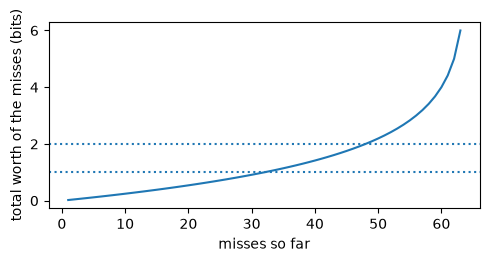

In [8]:
def miss_worth(k):
    return math.log2((65 - k) / (64 - k))        # shot k is a miss; 65-k squares before it

running = 0.0
print("shot  worth(miss)  total")
for k in range(1, 49):
    w = miss_worth(k); running += w
    if k in (1, 2, 3, 32, 33, 48):
        print(f"{k:4d}  {w:.4f}       {running:.4f}")

sum32 = sum(miss_worth(k) for k in range(1, 33))
sum48 = sum(miss_worth(k) for k in range(1, 49))
print(f"32 misses: {sum32:.4f}   48 misses: {sum48:.4f}   hit on shot 49 (16 squares): {math.log2(16):.4f}   total {sum48 + math.log2(16):.4f}")

totals = []
for t in range(1, 65):
    misses = sum(miss_worth(k) for k in range(1, t))
    totals.append(misses + math.log2(65 - t))
print("hit on shot t, total for t = 1..64: min %.6f  max %.6f" % (min(totals), max(totals)))
print("a hit on shot 1 is worth", math.log2(64), "; a hit on shot 64 is worth", math.log2(1), "(the last square is a certainty)")

fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(range(1, 64), np.cumsum([miss_worth(k) for k in range(1, 64)]))
ax.set_xlabel("misses so far"); ax.set_ylabel("total worth of the misses (bits)")
ax.axhline(1, ls=":"); ax.axhline(2, ls=":"); plt.tight_layout(); plt.show()

## Exercise 4. Whose model? The same snow, two forecasters

Ana believes the chance of snow tomorrow is 1/8; Ben believes it is 1/2. It snows. Compute each forecaster's surprisal and the gap. Then ask: what if a forecaster had said the chance was exactly 0?

<details><summary>Hint</summary>

The number belongs to the *pair* (outcome, model), not to the outcome alone. For share 0 the formula `log2(1/p)` has no finite value; decide how your function should behave.

</details>

In [9]:
# your attempt

In [10]:
def surprisal_safe(p):
    return math.inf if p <= 0 else math.log2(1.0 / p)

ana, ben = surprisal_safe(1/8), surprisal_safe(1/2)
print(f"Ana {ana:.3f}  Ben {ben:.3f}  gap {ana - ben:.3f}")
print("a forecaster who said 0 and sees snow:", surprisal_safe(0.0))

Ana 3.000  Ben 1.000  gap 2.000
a forecaster who said 0 and sees snow: inf


## Exercise 5. Your own text: letter surprisal and a word-level toy

Set `MY_TEXT` to a paragraph of your own (a methods section, a news article). Lower-case it, keep the 26 letters and the space (27 symbols), and compute (a) the share and surprisal of each symbol, (b) the entropy of the letter distribution. Then (c), word level: split into words, estimate a *unigram* model (each word's share in the text), and list the three word types that contribute most bits in total (count times surprisal).

The sample text below is ours. Replace it with yours and compare. Your number will differ from MacKay's 4.11 (MacKay 2003, p. 32) and from Shannon's 4.03 for 27 symbols (Shannon 1951, p. 54): different texts, and a short text gives a noisy estimate. Do not mix the two published numbers.

<details><summary>Hint</summary>

`Counter` counts symbols. For (c), `bits = count * log2(N / count)` where N is the number of word tokens. The word model is estimated from the same text it scores, so it is *a model, not a mind*: it says nothing about what a reader finds surprising.

</details>

In [11]:
# your attempt
MY_TEXT = "..."

In [12]:
MY_TEXT = (
    "We estimate how often each topic appears in a day of posts and ask how much a typical post tells us "
    "about the topic mix. A day with one dominant topic is easy to predict, and a day with many equally "
    "likely topics is hard to predict. We therefore compare the average number of yes or no questions "
    "needed to name the topic of a random post before and after the event. The estimate depends on the "
    "sample size, so we report intervals and we repeat the analysis on random halves of the data."
)

def clean(text):
    text = text.lower()
    return "".join(ch if ("a" <= ch <= "z") else " " for ch in text)

symbols = " ".join(clean(MY_TEXT).split())            # 27 symbols: a-z and single spaces
counts = Counter(symbols)
N = sum(counts.values())
shares = {ch: c / N for ch, c in counts.items()}
H_letters = entropy(shares.values())
print(f"{N} symbols, {len(counts)} distinct; letter entropy {H_letters:.3f} bits per symbol (log2 27 = {math.log2(27):.3f})")
print("most surprising symbols:", sorted(((round(surprisal(p), 2), ch if ch != ' ' else '<space>') for ch, p in shares.items()), reverse=True)[:5])
print("least surprising symbols:", sorted(((round(surprisal(p), 2), ch if ch != ' ' else '<space>') for ch, p in shares.items()))[:3])

words = symbols.split()
wc = Counter(words); T = len(words)
tot_bits = {w: c * math.log2(T / c) for w, c in wc.items()}
top = sorted(tot_bits.items(), key=lambda kv: -kv[1])[:3]
print(f"{T} word tokens, {len(wc)} word types")
print("word types with most total bits (count x surprisal):", [(w, wc[w], round(b, 1)) for w, b in top])
print("a model, not a mind: each word's share comes from this same text, so a word seen once costs", round(math.log2(T), 2), "bits")

480 symbols, 26 distinct; letter entropy 4.012 bits per symbol (log2 27 = 4.755)
most surprising symbols: [(8.91, 'z'), (8.91, 'x'), (8.91, 'g'), (7.91, 'q'), (7.91, 'k')]
least surprising symbols: [(2.37, '<space>'), (3.18, 'e'), (3.58, 'a')]
94 word tokens, 59 word types
word types with most total bits (count x surprisal): [('the', 8, 28.4), ('a', 5, 21.2), ('we', 4, 18.2)]
a model, not a mind: each word's share comes from this same text, so a word seen once costs 6.55 bits


## Exercise 6. Estimation bias: a small sample makes the entropy look too small

In practice the shares are estimated from data. Draw n village days, count each word, plug the observed shares into the entropy formula (the *plug-in* estimate), and repeat 2,000 times for n = 10, 30, 100 and 1,000. The true entropy is 1.75. Report the mean estimate, its gap from 1.75, and the standard error of the mean.

Predict first: too high or too low for n = 10? Why?

<details><summary>Hint</summary>

`rng.multinomial(n, SHARES, size=2000)` gives the counts for 2,000 repeats at once. A small sample may miss the rare words entirely, and a word you never saw gets share 0.

</details>

In [13]:
# your attempt

true entropy 1.7500; 2000 repeats per n
    n   mean plug-in H   gap from true   std. error of the mean
   10   1.5036           -0.2464          0.0071
   30   1.6753           -0.0747          0.0037
  100   1.7253           -0.0247          0.0019
 1000   1.7469           -0.0031          0.0006


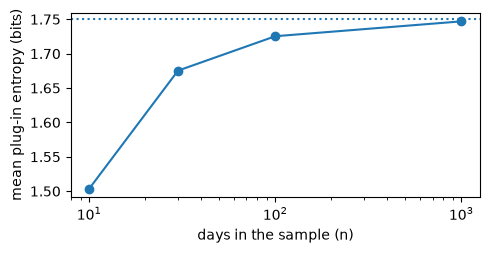

In [14]:
rng6 = np.random.default_rng(SEED + 6)
true_H = entropy(SHARES)
REPS = 2000
print(f"true entropy {true_H:.4f}; {REPS} repeats per n")
print("    n   mean plug-in H   gap from true   std. error of the mean")
bias_rows = []
for n in (10, 30, 100, 1000):
    c = rng6.multinomial(n, SHARES, size=REPS)
    p = c / n
    with np.errstate(divide="ignore", invalid="ignore"):
        h = -np.nansum(np.where(p > 0, p * np.log2(p), 0.0), axis=1)
    bias_rows.append((n, h.mean(), h.mean() - true_H, h.std(ddof=1) / math.sqrt(REPS)))
    print(f"{n:5d}   {h.mean():.4f}           {h.mean() - true_H:+.4f}          {h.std(ddof=1)/math.sqrt(REPS):.4f}")

fig, ax = plt.subplots(figsize=(5, 2.6))
ax.semilogx([r[0] for r in bias_rows], [r[1] for r in bias_rows], "o-")
ax.axhline(true_H, ls=":"); ax.set_xlabel("days in the sample (n)"); ax.set_ylabel("mean plug-in entropy (bits)")
plt.tight_layout(); plt.show()

## Exercise 7 (extension). The weighing: which first weighing is worth most?

This one is a fold-out in the post (step 3), so treat it as optional. Twelve balls; one is heavier or lighter (24 hypotheses: ball 1 to 12, heavy or light). Put k balls in each pan (the rest stay off the scale). The scale shows *left down*, *right down* or *balance*. (a) For k = 1 to 6, compute the chance of each outcome (all 24 hypotheses equally likely) and the entropy of the outcome. (b) For 4 against 4 and for 6 against 6, count how many of the 24 hypotheses are still possible after each outcome.

Predict first: which k is best? For 6 against 6, how many hypotheses are left after *left down*?

<details><summary>Hint</summary>

A hypothesis is a pair (ball, heavy or light). An outcome is a function of the pair and of k: a ball in the left pan that is heavy, or a ball in the right pan that is light, makes the left pan go down. Use `Counter` to count outcomes over all 24 pairs.

</details>

In [15]:
# your attempt

In [16]:
HYP = [(b, d) for b in range(1, 13) for d in ("heavy", "light")]      # 24 hypotheses

def outcome(h, k):
    ball, d = h
    on_left, on_right = ball <= k, k < ball <= 2 * k
    if not (on_left or on_right):
        return "balance"
    left_down = (on_left and d == "heavy") or (on_right and d == "light")
    return "left down" if left_down else "right down"

def H_of(counter):
    n = sum(counter.values())
    return entropy([c / n for c in counter.values()])

print("k  chances (left down, right down, balance)   outcome entropy")
for k in range(1, 7):
    c = Counter(outcome(h, k) for h in HYP)
    ch = [c["left down"] / 24, c["right down"] / 24, c["balance"] / 24]
    print(f"{k}  {ch[0]:.3f} {ch[1]:.3f} {ch[2]:.3f}                         {H_of(c):.3f}")
print(f"all 24 hypotheses: log2(24) = {math.log2(24):.3f} bits")

for k in (4, 6):
    c = Counter(outcome(h, k) for h in HYP)
    print(f"{k} against {k}: hypotheses left after left down / right down / balance: {c['left down']}, {c['right down']}, {c['balance']} of 24")

k  chances (left down, right down, balance)   outcome entropy
1  0.083 0.083 0.833                         0.817
2  0.167 0.167 0.667                         1.252
3  0.250 0.250 0.500                         1.500
4  0.333 0.333 0.333                         1.585
5  0.417 0.417 0.167                         1.483
6  0.500 0.500 0.000                         1.000
all 24 hypotheses: log2(24) = 4.585 bits
4 against 4: hypotheses left after left down / right down / balance: 8, 8, 8 of 24
6 against 6: hypotheses left after left down / right down / balance: 12, 12, 0 of 24


## Exercise 8. Building the best script, and the bound H <= EQ < H + 1

The post says (step 6) how to build the best script of whole questions: repeatedly join the two rarest outcomes into one group, and every outcome inside the group gets one more question. This is the Huffman method; the post labels the rule as ours, not from its sources. The average length is `EQ = sum of share times script length`.

(a) Three outcomes with shares 1/2, 1/4, 1/4: join by hand, write the lengths, and compute EQ and H. (b) Write `huffman_lengths(shares)` with `heapq` and run it on the 0.7 village (shares 0.7, 0.1, 0.1, 0.1) and on the weather village. (c) For 1,050 random share vectors (150 for each number of outcomes) on 4 to 10 outcomes, check `H <= EQ < H + 1` and report the smallest and largest gap EQ - H. (d) Transfer: the market stall of the post (shares 1/4, 1/4, 1/4, 1/8, 1/8): what does the best script cost, and what does the old script (1, 2, 3, 4, 4) cost?

Predict first: for which shares is EQ exactly H?

<details><summary>Hint</summary>

Keep a heap of `(share, tiebreak, [outcome indices])`. Each time two groups are joined, every outcome inside them gets one more question. The tiebreak counter stops Python from comparing the lists. If you are stuck, do (a) on paper first: the two 1/4 shares join into a group of 1/2, which then joins the other 1/2.

</details>

In [17]:
# your attempt

In [18]:
def huffman_lengths(shares, trace=False):
    counter = itertools.count()
    heap = [(p, next(counter), [i]) for i, p in enumerate(shares)]
    heapq.heapify(heap)
    lengths = [0] * len(shares)
    while len(heap) > 1:
        a = heapq.heappop(heap); b = heapq.heappop(heap)
        if trace:
            print(f"  join {a[0]:.2f} and {b[0]:.2f} into {a[0] + b[0]:.2f}; outcomes {sorted(a[2] + b[2])} get one more question")
        for i in a[2] + b[2]:
            lengths[i] += 1
        heapq.heappush(heap, (a[0] + b[0], next(counter), a[2] + b[2]))
    return lengths

def avg_len(shares, lengths):
    return sum(p * l for p, l in zip(shares, lengths))

three = [1/2, 1/4, 1/4]
print("three outcomes (1/2, 1/4, 1/4):")
L3 = huffman_lengths(three, trace=True)
print(f"  lengths {L3}, EQ = {avg_len(three, L3):.3f}, H = {entropy(three):.3f}")

v07 = [0.7, 0.1, 0.1, 0.1]
print("0.7 village:")
L = huffman_lengths(v07, trace=True)
print(f"0.7 village: H = {entropy(v07):.3f}, lengths {sorted(L)}, EQ = {avg_len(v07, L):.3f}, H + 1 = {entropy(v07) + 1:.3f}")
Lv = huffman_lengths(SHARES)
print(f"weather village: H = {entropy(SHARES):.3f}, EQ = {avg_len(SHARES, Lv):.3f}")

rng8 = np.random.default_rng(SEED + 8)
gaps, ok = [], True
for n in range(4, 11):
    for _ in range(150):
        p = rng8.dirichlet(np.ones(n)).tolist()
        l = huffman_lengths(p); H = entropy(p); eq = avg_len(p, l)
        ok &= (H <= eq + 1e-12) and (eq < H + 1)
        gaps.append(eq - H)
print(f"{len(gaps)} random share vectors on 4 to 10 outcomes: H <= EQ < H + 1 holds for all: {ok}")
print(f"gap EQ - H: smallest {min(gaps):.4f}, largest {max(gaps):.4f}")

# transfer: the market stall of the post
stall = [1/2, 1/4, 1/8, 1/16, 1/16]; Ls = huffman_lengths(stall)
print("stall: lengths", sorted(Ls), "EQ", avg_len(stall, Ls), "H", entropy(stall))
stall2 = [1/4, 1/4, 1/4, 1/8, 1/8]; Ls2 = huffman_lengths(stall2)
print("stall after the change: old script (1,2,3,4,4) costs", avg_len(stall2, [1, 2, 3, 4, 4]), "; best lengths", sorted(Ls2), "cost", avg_len(stall2, Ls2), "; H", entropy(stall2))

three outcomes (1/2, 1/4, 1/4):
  join 0.25 and 0.25 into 0.50; outcomes [1, 2] get one more question
  join 0.50 and 0.50 into 1.00; outcomes [0, 1, 2] get one more question
  lengths [1, 2, 2], EQ = 1.500, H = 1.500
0.7 village:
  join 0.10 and 0.10 into 0.20; outcomes [1, 2] get one more question
  join 0.10 and 0.20 into 0.30; outcomes [1, 2, 3] get one more question
  join 0.30 and 0.70 into 1.00; outcomes [0, 1, 2, 3] get one more question
0.7 village: H = 1.357, lengths [1, 2, 3, 3], EQ = 1.500, H + 1 = 2.357
weather village: H = 1.750, EQ = 1.750
1050 random share vectors on 4 to 10 outcomes: H <= EQ < H + 1 holds for all: True
gap EQ - H: smallest 0.0019, largest 0.6301
stall: lengths [1, 2, 3, 4, 4] EQ 1.875 H 1.875
stall after the change: old script (1,2,3,4,4) costs 2.5 ; best lengths [2, 2, 2, 3, 3] cost 2.25 ; H 2.25


## Where to go next

* Change the shares in `SHARES` and the script in `SCRIPT`, and watch exercise 2 change. A script is only right for the shares it was built for.
* Exercise 5 on a text of yours: how many symbols do you need before the letter entropy stops moving? (Exercise 6 says why it moves.)
* A transfer question for your own work: if you score posts with a language model's token probabilities, whose model is it (exercise 4), and how many posts did it see (exercise 6)?